In [4]:
!pip install pyarrow


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [5]:
from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_ROOT = Path.cwd().parent
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
RAW_DIR = PROJECT_ROOT / "data" / "raw"
FFIEC_DIR = RAW_DIR / "ffiec"
RESULTS_DIR = PROJECT_ROOT / "results"

In [6]:
records = []

for path in RAW_DIR.rglob("*"):
    if path.is_file():
        relative = path.relative_to(RAW_DIR)
        parts = relative.parts
        
        source = parts[0] if len(parts) >= 1 else "unknown"
        
        records.append({
            "source": source,
            "file_name": path.name,
            "extension": path.suffix.lower(),
            "size_mb": round(path.stat().st_size / (1024**2), 2),
            "relative_path": str(relative)
        })

raw_inventory = pd.DataFrame(records)

raw_inventory = raw_inventory.sort_values(
    ["source", "relative_path"]
).reset_index(drop=True)

print(f"Total raw files: {len(raw_inventory)}")

display(raw_inventory)

Total raw files: 48


,source,file_name,extension,size_mb,relative_path
0,.DS_Store,.DS_Store,,0.01,.DS_Store
1,bis,WS_LBS_D_PUB_csv_col.csv,.csv,512.45,bis/WS_LBS_D_PUB_csv_col.csv
2,eba,.DS_Store,,0.01,eba/.DS_Store
3,eba,2025 EU-wide stress test - Macro financial sce...,.xlsx,0.29,eba/stress_test_2025/2025 EU-wide stress test ...
4,eba,2025 EU-wide stress test - Market risk scenari...,.xlsx,1.58,eba/stress_test_2025/2025 EU-wide stress test ...
5,eba,2025 EU-wide stress test - Real GVA by sector....,.xlsx,0.14,eba/stress_test_2025/2025 EU-wide stress test ...
6,eba,Data_Dictionary.xlsx,.xlsx,0.03,eba/stress_test_2025/Data_Dictionary.xlsx
7,eba,Metadata_TR.xlsx,.xlsx,0.11,eba/stress_test_2025/Metadata_TR.xlsx
8,eba,Summary_of_Results_9_1_2026.csv,.csv,0.05,eba/stress_test_2025/Summary_of_Results_9_1_20...
9,eba,TRA_CRE_IRB.csv,.csv,59.33,eba/stress_test_2025/TRA_CRE_IRB.csv


In [7]:
source_summary = (
    raw_inventory
    .groupby("source")
    .agg(
        files=("file_name", "count"),
        total_size_mb=("size_mb", "sum")
    )
    .reset_index()
)

source_summary

,source,files,total_size_mb
0,.DS_Store,1,0.01
1,bis,1,512.45
2,eba,10,134.29
3,fdic,1,0.00
4,ffiec,25,170.15
5,fred,8,0.13
6,mtds,1,2.65
7,other,1,0.70


In [8]:
FFIEC_DIR = RAW_DIR / "ffiec"

ffiec_records = []

for path in FFIEC_DIR.rglob("*"):
    if path.is_file():
        relative = path.relative_to(FFIEC_DIR)
        
        ffiec_records.append({
            "year": relative.parts[0] if len(relative.parts) >= 1 else None,
            "file_name": path.name,
            "extension": path.suffix.lower(),
            "size_mb": round(path.stat().st_size / (1024**2), 2),
            "path": str(path)
        })

ffiec_inventory = pd.DataFrame(ffiec_records)

display(ffiec_inventory)

,year,file_name,extension,size_mb,path
0,.DS_Store,.DS_Store,,0.02,/Users/irfanhussain/Desktop/systemic-risk-proj...
1,2022,.DS_Store,,0.01,/Users/irfanhussain/Desktop/systemic-risk-proj...
2,2022,part2.txt,.txt,10.52,/Users/irfanhussain/Desktop/systemic-risk-proj...
3,2022,part1.txt,.txt,10.24,/Users/irfanhussain/Desktop/systemic-risk-proj...
4,2025,.DS_Store,,0.01,/Users/irfanhussain/Desktop/systemic-risk-proj...
5,2025,part2.txt,.txt,9.00,/Users/irfanhussain/Desktop/systemic-risk-proj...
6,2025,part1.txt,.txt,9.70,/Users/irfanhussain/Desktop/systemic-risk-proj...
7,2024,.DS_Store,,0.01,/Users/irfanhussain/Desktop/systemic-risk-proj...
8,2024,part2.txt,.txt,9.19,/Users/irfanhussain/Desktop/systemic-risk-proj...
9,2024,part1.txt,.txt,9.95,/Users/irfanhussain/Desktop/systemic-risk-proj...


In [9]:
ffiec_inventory.pivot_table(
    index="year",
    columns="file_name",
    values="size_mb",
    aggfunc="first"
)

file_name,.DS_Store,part1.txt,part2.txt
year,,,
.DS_Store,0.02,NaN,NaN
2018,0.01,11.74,12.98
2019,0.01,11.33,11.79
2020,0.01,10.88,11.13
2021,0.01,10.56,10.79
2022,0.01,10.24,10.52
2023,0.01,10.00,10.25
2024,0.01,9.95,9.19
2025,0.01,9.70,9.00


In [10]:
def load_ffiec_file(path):
    """
    Load a raw FFIEC tab-delimited Call Report file
    without changing the raw values.
    """
    
    df = pd.read_csv(
        path,
        sep="\t",
        dtype=str,
        low_memory=False
    )
    
    return df

In [11]:
sample_path = FFIEC_DIR / "2022" / "part1.txt"

df_sample = load_ffiec_file(sample_path)

print("Shape:", df_sample.shape)

Shape: (19218, 254)


In [12]:
def is_metadata_row(row):
    return (
        pd.isna(row.get("IDRSSD")) and
        pd.isna(row.get("Reporting Period End Date"))
    )

In [13]:
print("First row is metadata:", is_metadata_row(df_sample.iloc[0]))
print("Second row is metadata:", is_metadata_row(df_sample.iloc[1]))

First row is metadata: True
Second row is metadata: False


In [14]:
def audit_ffiec(df, name="FFIEC file"):
    
    print("=" * 60)
    print(name)
    print("=" * 60)
    
    print("Rows:", len(df))
    print("Columns:", len(df.columns))
    
    if "IDRSSD" in df.columns:
        ids = df["IDRSSD"].dropna()
        print("Unique IDRSSD:", ids.nunique())
        print("Missing IDRSSD:", df["IDRSSD"].isna().sum())
    
    if "Reporting Period End Date" in df.columns:
        dates = pd.to_datetime(
            df["Reporting Period End Date"],
            errors="coerce"
        )
        
        print("Date range:", dates.min(), "→", dates.max())
        print("Invalid/missing dates:", dates.isna().sum())
    
    print("Duplicate complete rows:", df.duplicated().sum())

In [15]:
audit_ffiec(df_sample, "2022 Part 1")

2022 Part 1
Rows: 19218
Columns: 254
Unique IDRSSD: 4859
Missing IDRSSD: 1
Date range: 2022-03-31 00:00:00 → 2022-12-31 00:00:00
Invalid/missing dates: 1
Duplicate complete rows: 0


In [16]:
df_test = df_sample.loc[
    ~df_sample.apply(is_metadata_row, axis=1)
].copy()

df_test["IDRSSD"] = df_test["IDRSSD"].astype("string")
df_test["Reporting Period End Date"] = pd.to_datetime(
    df_test["Reporting Period End Date"],
    errors="coerce"
)

key_duplicates = (
    df_test
    .duplicated(
        subset=["IDRSSD", "Reporting Period End Date"]
    )
    .sum()
)

print("Bank-quarter observations:", len(df_test))
print("Unique bank-quarter keys:", 
      df_test[["IDRSSD", "Reporting Period End Date"]]
      .drop_duplicates()
      .shape[0])

print("Duplicate bank-quarter keys:", key_duplicates)

Bank-quarter observations: 19217
Unique bank-quarter keys: 19217
Duplicate bank-quarter keys: 0


In [17]:
raw_inventory = raw_inventory[
    raw_inventory["file_name"] != ".DS_Store"
].copy()

raw_inventory = raw_inventory.reset_index(drop=True)

print(f"Actual raw files: {len(raw_inventory)}")
display(raw_inventory)

Actual raw files: 37


,source,file_name,extension,size_mb,relative_path
0,bis,WS_LBS_D_PUB_csv_col.csv,.csv,512.45,bis/WS_LBS_D_PUB_csv_col.csv
1,eba,2025 EU-wide stress test - Macro financial sce...,.xlsx,0.29,eba/stress_test_2025/2025 EU-wide stress test ...
2,eba,2025 EU-wide stress test - Market risk scenari...,.xlsx,1.58,eba/stress_test_2025/2025 EU-wide stress test ...
3,eba,2025 EU-wide stress test - Real GVA by sector....,.xlsx,0.14,eba/stress_test_2025/2025 EU-wide stress test ...
4,eba,Data_Dictionary.xlsx,.xlsx,0.03,eba/stress_test_2025/Data_Dictionary.xlsx
5,eba,Metadata_TR.xlsx,.xlsx,0.11,eba/stress_test_2025/Metadata_TR.xlsx
6,eba,Summary_of_Results_9_1_2026.csv,.csv,0.05,eba/stress_test_2025/Summary_of_Results_9_1_20...
7,eba,TRA_CRE_IRB.csv,.csv,59.33,eba/stress_test_2025/TRA_CRE_IRB.csv
8,eba,TRA_CRE_STA.csv,.csv,66.81,eba/stress_test_2025/TRA_CRE_STA.csv
9,eba,TRA_OTH.csv,.csv,5.94,eba/stress_test_2025/TRA_OTH.csv


In [18]:
def audit_ffiec_file(path):
    """
    Load and audit one FFIEC file.
    Raw file is not modified.
    """

    df = pd.read_csv(
        path,
        sep="\t",
        dtype=str,
        low_memory=False
    )

    # Identify metadata row
    metadata_row = (
        pd.isna(df["IDRSSD"].iloc[0])
        and pd.isna(df["Reporting Period End Date"].iloc[0])
    )

    # Remove metadata row only from the working copy
    if metadata_row:
        data = df.iloc[1:].copy()
    else:
        data = df.copy()

    # Parse date only in working copy
    dates = pd.to_datetime(
        data["Reporting Period End Date"],
        errors="coerce"
    )

    # Bank-period key
    key = data[["IDRSSD", "Reporting Period End Date"]].dropna()

    return {
        "year": path.parent.name,
        "part": path.stem.lower(),
        "file": path.name,
        "rows_raw": len(df),
        "rows_data": len(data),
        "columns": len(df.columns),
        "unique_idrssd": data["IDRSSD"].nunique(dropna=True),
        "missing_idrssd": data["IDRSSD"].isna().sum(),
        "missing_dates": dates.isna().sum(),
        "date_min": dates.min(),
        "date_max": dates.max(),
        "duplicate_bank_period": key.duplicated().sum(),
        "metadata_row_detected": metadata_row
    }

In [19]:
ffiec_results = []

for path in sorted(FFIEC_DIR.rglob("*.txt")):
    result = audit_ffiec_file(path)
    ffiec_results.append(result)

ffiec_audit = pd.DataFrame(ffiec_results)

ffiec_audit = ffiec_audit.sort_values(
    ["year", "part"]
).reset_index(drop=True)

display(ffiec_audit)

,year,part,file,rows_raw,rows_data,columns,unique_idrssd,missing_idrssd,missing_dates,date_min,date_max,duplicate_bank_period,metadata_row_detected
0,2018,part1,part1.txt,22234,22233,254,5662,0,0,2018-03-31,2018-12-31,0,True
1,2018,part2,part2.txt,22234,22233,242,5662,0,0,2018-03-31,2018-12-31,0,True
2,2019,part1,part1.txt,21299,21298,254,5425,0,0,2019-03-31,2019-12-31,0,True
3,2019,part2,part2.txt,21299,21298,226,5425,0,0,2019-03-31,2019-12-31,0,True
4,2020,part1,part1.txt,20412,20411,254,5171,0,0,2020-03-31,2020-12-31,0,True
5,2020,part2,part2.txt,20412,20411,226,5171,0,0,2020-03-31,2020-12-31,0,True
6,2021,part1,part1.txt,19875,19874,254,5035,0,0,2021-03-31,2021-12-31,0,True
7,2021,part2,part2.txt,19875,19874,226,5035,0,0,2021-03-31,2021-12-31,0,True
8,2022,part1,part1.txt,19218,19217,254,4859,0,0,2022-03-31,2022-12-31,0,True
9,2022,part2,part2.txt,19218,19217,226,4859,0,0,2022-03-31,2022-12-31,0,True


In [20]:
display(
    ffiec_audit[
        [
            "year",
            "part",
            "rows_data",
            "columns",
            "unique_idrssd",
            "missing_idrssd",
            "missing_dates",
            "duplicate_bank_period",
            "date_min",
            "date_max"
        ]
    ]
)

,year,part,rows_data,columns,unique_idrssd,missing_idrssd,missing_dates,duplicate_bank_period,date_min,date_max
0,2018,part1,22233,254,5662,0,0,0,2018-03-31,2018-12-31
1,2018,part2,22233,242,5662,0,0,0,2018-03-31,2018-12-31
2,2019,part1,21298,254,5425,0,0,0,2019-03-31,2019-12-31
3,2019,part2,21298,226,5425,0,0,0,2019-03-31,2019-12-31
4,2020,part1,20411,254,5171,0,0,0,2020-03-31,2020-12-31
5,2020,part2,20411,226,5171,0,0,0,2020-03-31,2020-12-31
6,2021,part1,19874,254,5035,0,0,0,2021-03-31,2021-12-31
7,2021,part2,19874,226,5035,0,0,0,2021-03-31,2021-12-31
8,2022,part1,19217,254,4859,0,0,0,2022-03-31,2022-12-31
9,2022,part2,19217,226,4859,0,0,0,2022-03-31,2022-12-31


In [21]:
year_part_check = (
    ffiec_audit
    .groupby("year")["part"]
    .agg(list)
)

display(year_part_check)

year
2018    [part1, part2]
2019    [part1, part2]
2020    [part1, part2]
2021    [part1, part2]
2022    [part1, part2]
2023    [part1, part2]
2024    [part1, part2]
2025    [part1, part2]
Name: part, dtype: object

In [22]:
for year, parts in year_part_check.items():
    if set(parts) != {"part1", "part2"}:
        print("PROBLEM:", year, parts)

In [23]:
def compare_ffiec_parts(year):
    
    part1_path = FFIEC_DIR / str(year) / "part1.txt"
    part2_path = FFIEC_DIR / str(year) / "part2.txt"

    p1 = pd.read_csv(
        part1_path,
        sep="\t",
        dtype=str,
        low_memory=False
    ).iloc[1:].copy()

    p2 = pd.read_csv(
        part2_path,
        sep="\t",
        dtype=str,
        low_memory=False
    ).iloc[1:].copy()

    # Institution comparison
    ids1 = set(p1["IDRSSD"].dropna())
    ids2 = set(p2["IDRSSD"].dropna())

    # Bank-quarter keys
    keys1 = set(
        zip(
            p1["IDRSSD"],
            p1["Reporting Period End Date"]
        )
    )

    keys2 = set(
        zip(
            p2["IDRSSD"],
            p2["Reporting Period End Date"]
        )
    )

    return {
        "year": year,
        "p1_ids": len(ids1),
        "p2_ids": len(ids2),
        "only_p1_ids": len(ids1 - ids2),
        "only_p2_ids": len(ids2 - ids1),
        "common_ids": len(ids1 & ids2),
        "p1_keys": len(keys1),
        "p2_keys": len(keys2),
        "only_p1_keys": len(keys1 - keys2),
        "only_p2_keys": len(keys2 - keys1),
        "common_keys": len(keys1 & keys2),
    }

In [24]:
part_comparison = pd.DataFrame(
    [compare_ffiec_parts(year) for year in range(2018, 2026)]
)

display(part_comparison)

,year,p1_ids,p2_ids,only_p1_ids,only_p2_ids,common_ids,p1_keys,p2_keys,only_p1_keys,only_p2_keys,common_keys
0,2018,5662,5662,0,0,5662,22233,22233,0,0,22233
1,2019,5425,5425,0,0,5425,21298,21298,0,0,21298
2,2020,5171,5171,0,0,5171,20411,20411,0,0,20411
3,2021,5035,5035,0,0,5035,19874,19874,0,0,19874
4,2022,4859,4859,0,0,4859,19217,19217,0,0,19217
5,2023,4732,4732,0,0,4732,18731,18731,0,0,18731
6,2024,4630,4630,0,0,4630,18332,18332,0,0,18332
7,2025,4522,4522,0,0,4522,17825,17825,0,0,17825


In [25]:
schema_info = {}

for year in range(2018, 2026):

    for part in ["part1", "part2"]:

        path = FFIEC_DIR / str(year) / f"{part}.txt"

        df = pd.read_csv(
            path,
            sep="\t",
            dtype=str,
            nrows=1
        )

        schema_info[(year, part)] = list(df.columns)

        print(
            f"{year} {part}: "
            f"{len(df.columns)} columns"
        )

2018 part1: 254 columns
2018 part2: 242 columns
2019 part1: 254 columns
2019 part2: 226 columns
2020 part1: 254 columns
2020 part2: 226 columns
2021 part1: 254 columns
2021 part2: 226 columns
2022 part1: 254 columns
2022 part2: 226 columns
2023 part1: 254 columns
2023 part2: 226 columns
2024 part1: 254 columns
2024 part2: 185 columns
2025 part1: 254 columns
2025 part2: 185 columns


In [26]:
reference_year = 2022

for part in ["part1", "part2"]:

    reference = set(schema_info[(reference_year, part)])

    print("\n" + "=" * 70)
    print(f"{part.upper()} schema comparison against {reference_year}")
    print("=" * 70)

    for year in range(2018, 2026):

        current = set(schema_info[(year, part)])

        added = current - reference
        removed = reference - current

        print(
            f"{year}: "
            f"columns={len(current)}, "
            f"added={len(added)}, "
            f"removed={len(removed)}"
        )


PART1 schema comparison against 2022
2018: columns=254, added=12, removed=12
2019: columns=254, added=0, removed=0
2020: columns=254, added=0, removed=0
2021: columns=254, added=0, removed=0
2022: columns=254, added=0, removed=0
2023: columns=254, added=0, removed=0
2024: columns=254, added=9, removed=9
2025: columns=254, added=9, removed=9

PART2 schema comparison against 2022
2018: columns=242, added=19, removed=3
2019: columns=226, added=0, removed=0
2020: columns=226, added=0, removed=0
2021: columns=226, added=0, removed=0
2022: columns=226, added=0, removed=0
2023: columns=226, added=0, removed=0
2024: columns=185, added=4, removed=45
2025: columns=185, added=4, removed=45


In [27]:
RESULTS_TABLES = RESULTS_DIR / "tables"
RESULTS_TABLES.mkdir(parents=True, exist_ok=True)

ffiec_audit.to_csv(
    RESULTS_TABLES / "ffiec_file_audit.csv",
    index=False
)

part_comparison.to_csv(
    RESULTS_TABLES / "ffiec_part_comparison.csv",
    index=False
)

print("Audit tables saved.")

Audit tables saved.


# 2. FFIEC Variable Catalogue

The FFIEC data contains hundreds of reported variables.

Before processing observations, we will:
1. Catalogue variables across all years.
2. Identify variables that are consistently available.
3. Map variables into economic categories.
4. Select a small core feature set for the first prototype.

We inspect metadata first and postpone loading the full observations.

In [28]:
from pathlib import Path
import pandas as pd

In [29]:
def read_ffiec_metadata(path):
    """
    Read only the header and first descriptive row.
    This is much faster than loading the entire file.
    """

    df = pd.read_csv(
        path,
        sep="\t",
        dtype=str,
        nrows=1,
        low_memory=False
    )

    return pd.DataFrame({
        "column_number": range(len(df.columns)),
        "column_name": df.columns,
        "description": df.iloc[0].values
    })

In [30]:
ffiec_metadata = {}

for year in range(2018, 2026):
    for part in ["part1", "part2"]:

        path = FFIEC_DIR / str(year) / f"{part}.txt"

        if path.exists():
            meta = read_ffiec_metadata(path)
            ffiec_metadata[(year, part)] = meta

            print(
                f"{year} {part}: "
                f"{len(meta)} columns"
            )

2018 part1: 254 columns
2018 part2: 242 columns
2019 part1: 254 columns
2019 part2: 226 columns
2020 part1: 254 columns
2020 part2: 226 columns
2021 part1: 254 columns
2021 part2: 226 columns
2022 part1: 254 columns
2022 part2: 226 columns
2023 part1: 254 columns
2023 part2: 226 columns
2024 part1: 254 columns
2024 part2: 185 columns
2025 part1: 254 columns
2025 part2: 185 columns


In [31]:
catalogue_rows = []

for (year, part), meta in ffiec_metadata.items():

    temp = meta.copy()

    temp["year"] = year
    temp["part"] = part

    catalogue_rows.append(temp)

variable_catalogue = pd.concat(
    catalogue_rows,
    ignore_index=True
)

variable_catalogue = variable_catalogue[
    [
        "year",
        "part",
        "column_number",
        "column_name",
        "description"
    ]
]

display(variable_catalogue.head(20))

,year,part,column_number,column_name,description
0,2018,part1,0,Reporting Period End Date,NaN
1,2018,part1,1,IDRSSD,NaN
2,2018,part1,2,FDIC Certificate Number,NaN
3,2018,part1,3,OCC Charter Number,NaN
4,2018,part1,4,OTS Docket Number,NaN
5,2018,part1,5,Primary ABA Routing Number,NaN
6,2018,part1,6,Financial Institution Name,NaN
7,2018,part1,7,Financial Institution Address,NaN
8,2018,part1,8,Financial Institution City,NaN
9,2018,part1,9,Financial Institution State,NaN


In [32]:
identifier_columns = [
    "Reporting Period End Date",
    "IDRSSD",
    "FDIC Certificate Number",
    "OCC Charter Number",
    "OTS Docket Number",
    "Primary ABA Routing Number",
    "Financial Institution Name",
    "Financial Institution Address",
    "Financial Institution City",
    "Financial Institution State",
    "Financial Institution Zip Code",
    "Financial Institution Filing Type",
    "Last Date/Time Submission Updated On"
]

In [33]:
financial_catalogue = variable_catalogue[
    ~variable_catalogue["column_name"].isin(identifier_columns)
].copy()

print(
    "Total variable entries:",
    len(variable_catalogue)
)

print(
    "Financial variable entries:",
    len(financial_catalogue)
)

Total variable entries: 3774
Financial variable entries: 3566


In [34]:
def schema_stability(part):
    
    subset = variable_catalogue[
        variable_catalogue["part"] == part
    ]

    counts = (
        subset.groupby("column_name")["year"]
        .nunique()
        .reset_index(name="years_present")
    )

    counts["stable_all_years"] = (
        counts["years_present"] == 8
    )

    return counts.sort_values(
        ["stable_all_years", "years_present"],
        ascending=[False, False]
    )

In [35]:
part1_stability = schema_stability("part1")
part2_stability = schema_stability("part2")

display(part1_stability.head(30))
display(part2_stability.head(30))

,column_name,years_present,stable_all_years
0,FDIC Certificate Number,8,True
1,Financial Institution Address,8,True
2,Financial Institution City,8,True
3,Financial Institution Filing Type,8,True
4,Financial Institution Name,8,True
5,Financial Institution State,8,True
6,Financial Institution Zip Code,8,True
7,IDRSSD,8,True
8,Last Date/Time Submission Updated On,8,True
9,OCC Charter Number,8,True


,column_name,years_present,stable_all_years
0,FDIC Certificate Number,8,True
1,Financial Institution Address,8,True
2,Financial Institution City,8,True
3,Financial Institution Filing Type,8,True
4,Financial Institution Name,8,True
5,Financial Institution State,8,True
6,Financial Institution Zip Code,8,True
7,IDRSSD,8,True
8,Last Date/Time Submission Updated On,8,True
9,OCC Charter Number,8,True


In [36]:
financial_keywords = {
    "assets": [
        "TOTAL ASSETS"
    ],

    "equity": [
        "EQUITY CAPITAL, TOTAL",
        "TOTAL EQUITY"
    ],

    "deposits": [
        "TOTAL DEPOSITS"
    ],

    "loans": [
        "TOTAL LOANS",
        "TOTAL LOANS AND LEASES"
    ],

    "income": [
        "NET INCOME",
        "NET INTEREST INCOME"
    ],

    "interest": [
        "TOTAL INTEREST INCOME",
        "TOTAL INTEREST EXPENSE"
    ],

    "asset_quality": [
        "NONACCRUAL",
        "PAST DUE"
    ],

    "loan_loss": [
        "PROVISION FOR LOAN"
    ]
}

In [37]:
for category, terms in financial_keywords.items():

    mask = pd.Series(
        False,
        index=financial_catalogue.index
    )

    for term in terms:
        mask |= (
            financial_catalogue["description"]
            .astype(str)
            .str.upper()
            .str.contains(term, regex=False)
        )

    result = financial_catalogue.loc[
        mask,
        [
            "year",
            "part",
            "column_name",
            "description"
        ]
    ]

    print("\n" + "=" * 90)
    print(category.upper())
    print("=" * 90)

    display(result)


ASSETS


,year,part,column_name,description
38,2018,part1,RCFD2170,TOTAL ASSETS
190,2018,part1,RCON2170,TOTAL ASSETS
532,2019,part1,RCFD2170,TOTAL ASSETS
676,2019,part1,RCON2170,TOTAL ASSETS
1012,2020,part1,RCFD2170,TOTAL ASSETS
1156,2020,part1,RCON2170,TOTAL ASSETS
1492,2021,part1,RCFD2170,TOTAL ASSETS
1636,2021,part1,RCON2170,TOTAL ASSETS
1972,2022,part1,RCFD2170,TOTAL ASSETS
2116,2022,part1,RCON2170,TOTAL ASSETS



EQUITY


,year,part,column_name,description
46,2018,part1,RCFD3210,TOTAL EQUITY CAPITAL
199,2018,part1,RCON3210,TOTAL EQUITY CAPITAL
539,2019,part1,RCFD3210,TOTAL EQUITY CAPITAL
684,2019,part1,RCON3210,TOTAL EQUITY CAPITAL
1019,2020,part1,RCFD3210,TOTAL EQUITY CAPITAL
1164,2020,part1,RCON3210,TOTAL EQUITY CAPITAL
1499,2021,part1,RCFD3210,TOTAL EQUITY CAPITAL
1644,2021,part1,RCON3210,TOTAL EQUITY CAPITAL
1979,2022,part1,RCFD3210,TOTAL EQUITY CAPITAL
2124,2022,part1,RCON3210,TOTAL EQUITY CAPITAL



DEPOSITS


...

,year,part,column_name,description
412,2018,part2,RIAD4073,TOTAL INTEREST EXPENSE
418,2018,part2,RIAD4107,TOTAL INTEREST INCOME
892,2019,part2,RIAD4073,TOTAL INTEREST EXPENSE
898,2019,part2,RIAD4107,TOTAL INTEREST INCOME
1372,2020,part2,RIAD4073,TOTAL INTEREST EXPENSE
1378,2020,part2,RIAD4107,TOTAL INTEREST INCOME
1852,2021,part2,RIAD4073,TOTAL INTEREST EXPENSE
1858,2021,part2,RIAD4107,TOTAL INTEREST INCOME
2332,2022,part2,RIAD4073,TOTAL INTEREST EXPENSE
2338,2022,part2,RIAD4107,TOTAL INTEREST INCOME



ASSET_QUALITY


,year,part,column_name,description
21,2018,part1,RCFD1253,"C&I LNS TO US ADDRS,NONACCRUAL"
24,2018,part1,RCFD1256,"C&I LNS TO NONUS ADR,NONACCRUAL"
25,2018,part1,RCFD1403,"TOTAL, NONACCRUAL"
26,2018,part1,RCFD1406,"TOTAL, PAST DUE 30-89 DAYS, ACCRUING"
27,2018,part1,RCFD1407,"TOTAL, PAST DUE 90 OR MORE, ACCRUING"
...,...,...,...,...
3584,2025,part1,RCONF176,1-4 FAM RES CNSTRCTN LN NONACCRUAL
3585,2025,part1,RCONF177,OTHER CNSTRCTN LN NONACCRUAL
3612,2025,part2,RCONHK28,TOTAL LN MOD FIN DFCLTY NONACCRUAL
3659,2025,part2,RCONK215,AUTO LN TO IND HH FAM NONACCRUAL



LOAN_LOSS


,year,part,column_name,description
974,2019,part2,RIADJJ33,Provision for loan and lease losses
1454,2020,part2,RIADJJ33,Provision for loan and lease losses
1934,2021,part2,RIADJJ33,Provision for loan and lease losses
2414,2022,part2,RIADJJ33,Provision for loan and lease losses
2894,2023,part2,RIADJJ33,Provision for loan and lease losses


In [38]:
description_changes = (
    variable_catalogue
    .groupby("column_name")["description"]
    .nunique(dropna=False)
    .reset_index(name="different_descriptions")
)

description_changes = description_changes.sort_values(
    "different_descriptions",
    ascending=False
)

display(
    description_changes.head(30)
)

,column_name,different_descriptions
130,RCFDK127,2
349,RCONK120,2
360,RCONK132,2
359,RCONK131,2
105,RCFDHK28,2
104,RCFDHK27,2
103,RCFDHK26,2
358,RCONK130,2
357,RCONK128,2
356,RCONK127,2


In [39]:
catalogue_path = RESULTS_DIR / "tables"
catalogue_path.mkdir(
    parents=True,
    exist_ok=True
)

variable_catalogue.to_csv(
    catalogue_path / "ffiec_variable_catalogue.csv",
    index=False
)

part1_stability.to_csv(
    catalogue_path / "ffiec_part1_variable_stability.csv",
    index=False
)

part2_stability.to_csv(
    catalogue_path / "ffiec_part2_variable_stability.csv",
    index=False
)

print("Variable catalogues saved.")

Variable catalogues saved.


In [40]:
print(part1_stability[part1_stability["stable_all_years"]].shape)
print(part2_stability[part2_stability["stable_all_years"]].shape)

(233, 3)
(179, 3)


In [41]:
def find_exact_description(catalogue, phrase):
    mask = (
        catalogue["description"]
        .astype("string")
        .str.upper()
        .str.strip()
        == phrase.upper()
    )

    return catalogue.loc[
        mask,
        ["year", "part", "column_name", "description"]
    ].drop_duplicates()

In [42]:
phrases = [
    "TOTAL ASSETS",
    "TOTAL EQUITY CAPITAL",
    "TOTAL LOANS AND LEASES, NET OF UNEARNED INCOME",
    "TOTAL DEPOSITS",
    "NET INTEREST INCOME",
    "NET INCOME",
    "TOTAL, NONACCRUAL"
]

for phrase in phrases:
    print("\n" + "=" * 80)
    print(phrase)
    print("=" * 80)
    display(find_exact_description(variable_catalogue, phrase))


TOTAL ASSETS


,year,part,column_name,description
38,2018,part1,RCFD2170,TOTAL ASSETS
190,2018,part1,RCON2170,TOTAL ASSETS
532,2019,part1,RCFD2170,TOTAL ASSETS
676,2019,part1,RCON2170,TOTAL ASSETS
1012,2020,part1,RCFD2170,TOTAL ASSETS
1156,2020,part1,RCON2170,TOTAL ASSETS
1492,2021,part1,RCFD2170,TOTAL ASSETS
1636,2021,part1,RCON2170,TOTAL ASSETS
1972,2022,part1,RCFD2170,TOTAL ASSETS
2116,2022,part1,RCON2170,TOTAL ASSETS



TOTAL EQUITY CAPITAL


,year,part,column_name,description
46,2018,part1,RCFD3210,TOTAL EQUITY CAPITAL
199,2018,part1,RCON3210,TOTAL EQUITY CAPITAL
539,2019,part1,RCFD3210,TOTAL EQUITY CAPITAL
684,2019,part1,RCON3210,TOTAL EQUITY CAPITAL
1019,2020,part1,RCFD3210,TOTAL EQUITY CAPITAL
1164,2020,part1,RCON3210,TOTAL EQUITY CAPITAL
1499,2021,part1,RCFD3210,TOTAL EQUITY CAPITAL
1644,2021,part1,RCON3210,TOTAL EQUITY CAPITAL
1979,2022,part1,RCFD3210,TOTAL EQUITY CAPITAL
2124,2022,part1,RCON3210,TOTAL EQUITY CAPITAL



TOTAL LOANS AND LEASES, NET OF UNEARNED INCOME


...

,year,part,column_name,description
413,2018,part2,RIAD4074,NET INTEREST INCOME
893,2019,part2,RIAD4074,NET INTEREST INCOME
1373,2020,part2,RIAD4074,NET INTEREST INCOME
1853,2021,part2,RIAD4074,NET INTEREST INCOME
2333,2022,part2,RIAD4074,NET INTEREST INCOME
2813,2023,part2,RIAD4074,NET INTEREST INCOME
3254,2024,part2,RIAD4074,NET INTEREST INCOME
3693,2025,part2,RIAD4074,NET INTEREST INCOME



NET INCOME


,year,part,column_name,description
432,2018,part2,RIAD4340,NET INCOME
911,2019,part2,RIAD4340,NET INCOME
1391,2020,part2,RIAD4340,NET INCOME
1871,2021,part2,RIAD4340,NET INCOME
2351,2022,part2,RIAD4340,NET INCOME
2831,2023,part2,RIAD4340,NET INCOME
3272,2024,part2,RIAD4340,NET INCOME
3711,2025,part2,RIAD4340,NET INCOME



TOTAL, NONACCRUAL


,year,part,column_name,description
25,2018,part1,RCFD1403,"TOTAL, NONACCRUAL"
174,2018,part1,RCON1403,"TOTAL, NONACCRUAL"
520,2019,part1,RCFD1403,"TOTAL, NONACCRUAL"
661,2019,part1,RCON1403,"TOTAL, NONACCRUAL"
1000,2020,part1,RCFD1403,"TOTAL, NONACCRUAL"
1141,2020,part1,RCON1403,"TOTAL, NONACCRUAL"
1480,2021,part1,RCFD1403,"TOTAL, NONACCRUAL"
1621,2021,part1,RCON1403,"TOTAL, NONACCRUAL"
1960,2022,part1,RCFD1403,"TOTAL, NONACCRUAL"
2101,2022,part1,RCON1403,"TOTAL, NONACCRUAL"


In [43]:
def column_coverage(path, columns):
    df = pd.read_csv(
        path,
        sep="\t",
        dtype=str,
        low_memory=False
    )

    df = df.iloc[1:].copy()

    result = {}

    for col in columns:
        if col in df.columns:
            non_missing = df[col].notna().sum()
            non_blank = (
                df[col].astype("string").str.strip().ne("").sum()
            )

            result[col] = {
                "non_missing": non_missing,
                "non_blank": non_blank,
                "rows": len(df)
            }

    return pd.DataFrame(result).T

In [44]:
test_columns = [
    "RCFD2170",
    "RCON2170",
    "RCFD3210",
    "RCON3210",
    "RCFD2122",
    "RCON2122",
    "RCFN2200",
    "RCON2200",
    "RCFD1403",
    "RCON1403"
]

coverage_2022 = column_coverage(
    FFIEC_DIR / "2022" / "part1.txt",
    test_columns
)

display(coverage_2022)

,non_missing,non_blank,rows
RCFD2170,338,338,19217
RCON2170,18879,18879,19217
RCFD3210,338,338,19217
RCON3210,18879,18879,19217
RCFN2200,252,252,19217
RCON2200,19217,19217,19217
RCFD1403,338,338,19217
RCON1403,18879,18879,19217


In [45]:
for phrase in phrases:
    print("\n" + "=" * 80)
    print(phrase)
    print("=" * 80)
    display(find_exact_description(variable_catalogue, phrase))


TOTAL ASSETS


,year,part,column_name,description
38,2018,part1,RCFD2170,TOTAL ASSETS
190,2018,part1,RCON2170,TOTAL ASSETS
532,2019,part1,RCFD2170,TOTAL ASSETS
676,2019,part1,RCON2170,TOTAL ASSETS
1012,2020,part1,RCFD2170,TOTAL ASSETS
1156,2020,part1,RCON2170,TOTAL ASSETS
1492,2021,part1,RCFD2170,TOTAL ASSETS
1636,2021,part1,RCON2170,TOTAL ASSETS
1972,2022,part1,RCFD2170,TOTAL ASSETS
2116,2022,part1,RCON2170,TOTAL ASSETS



TOTAL EQUITY CAPITAL


,year,part,column_name,description
46,2018,part1,RCFD3210,TOTAL EQUITY CAPITAL
199,2018,part1,RCON3210,TOTAL EQUITY CAPITAL
539,2019,part1,RCFD3210,TOTAL EQUITY CAPITAL
684,2019,part1,RCON3210,TOTAL EQUITY CAPITAL
1019,2020,part1,RCFD3210,TOTAL EQUITY CAPITAL
1164,2020,part1,RCON3210,TOTAL EQUITY CAPITAL
1499,2021,part1,RCFD3210,TOTAL EQUITY CAPITAL
1644,2021,part1,RCON3210,TOTAL EQUITY CAPITAL
1979,2022,part1,RCFD3210,TOTAL EQUITY CAPITAL
2124,2022,part1,RCON3210,TOTAL EQUITY CAPITAL



TOTAL LOANS AND LEASES, NET OF UNEARNED INCOME


...

,year,part,column_name,description
413,2018,part2,RIAD4074,NET INTEREST INCOME
893,2019,part2,RIAD4074,NET INTEREST INCOME
1373,2020,part2,RIAD4074,NET INTEREST INCOME
1853,2021,part2,RIAD4074,NET INTEREST INCOME
2333,2022,part2,RIAD4074,NET INTEREST INCOME
2813,2023,part2,RIAD4074,NET INTEREST INCOME
3254,2024,part2,RIAD4074,NET INTEREST INCOME
3693,2025,part2,RIAD4074,NET INTEREST INCOME



NET INCOME


,year,part,column_name,description
432,2018,part2,RIAD4340,NET INCOME
911,2019,part2,RIAD4340,NET INCOME
1391,2020,part2,RIAD4340,NET INCOME
1871,2021,part2,RIAD4340,NET INCOME
2351,2022,part2,RIAD4340,NET INCOME
2831,2023,part2,RIAD4340,NET INCOME
3272,2024,part2,RIAD4340,NET INCOME
3711,2025,part2,RIAD4340,NET INCOME



TOTAL, NONACCRUAL


,year,part,column_name,description
25,2018,part1,RCFD1403,"TOTAL, NONACCRUAL"
174,2018,part1,RCON1403,"TOTAL, NONACCRUAL"
520,2019,part1,RCFD1403,"TOTAL, NONACCRUAL"
661,2019,part1,RCON1403,"TOTAL, NONACCRUAL"
1000,2020,part1,RCFD1403,"TOTAL, NONACCRUAL"
1141,2020,part1,RCON1403,"TOTAL, NONACCRUAL"
1480,2021,part1,RCFD1403,"TOTAL, NONACCRUAL"
1621,2021,part1,RCON1403,"TOTAL, NONACCRUAL"
1960,2022,part1,RCFD1403,"TOTAL, NONACCRUAL"
2101,2022,part1,RCON1403,"TOTAL, NONACCRUAL"


In [46]:
coverage_2022 = column_coverage(
    FFIEC_DIR / "2022" / "part1.txt",
    test_columns
)

display(coverage_2022)

,non_missing,non_blank,rows
RCFD2170,338,338,19217
RCON2170,18879,18879,19217
RCFD3210,338,338,19217
RCON3210,18879,18879,19217
RCFN2200,252,252,19217
RCON2200,19217,19217,19217
RCFD1403,338,338,19217
RCON1403,18879,18879,19217


In [47]:
# Use the already loaded 2022 Part 1 data
filing_types = (
    df_sample["Financial Institution Filing Type"]
    .value_counts(dropna=False)
)

display(filing_types)

Financial Institution Filing Type
051    14246
041     4633
031      338
NaN        1
Name: count, dtype: int64

In [48]:
display(
    df_sample[
        [
            "Financial Institution Filing Type",
            "IDRSSD",
            "Reporting Period End Date",
            "RCFD2170",
            "RCON2170"
        ]
    ].iloc[1:20]
)

,Financial Institution Filing Type,IDRSSD,Reporting Period End Date,RCFD2170,RCON2170
1,051,37,2022-12-31,NaN,81497
2,051,242,2022-12-31,NaN,56694
3,051,279,2022-12-31,NaN,416983
4,051,354,2022-12-31,NaN,55069
5,051,457,2022-12-31,NaN,72812
6,051,505,2022-12-31,NaN,753438
7,051,1155,2022-12-31,NaN,464756
8,051,1351,2022-12-31,NaN,198121
9,051,1454,2022-12-31,NaN,960547
10,051,1669,2022-12-31,NaN,399086


In [49]:
column_inventory = pd.DataFrame({
    "column_number": range(len(df_sample.columns)),
    "column_name": df_sample.columns,
    "description": df_sample.iloc[0].values
})

print("Variables:", len(column_inventory))
display(column_inventory.head())

Variables: 254


,column_number,column_name,description
0,0,Reporting Period End Date,NaN
1,1,IDRSSD,NaN
2,2,FDIC Certificate Number,NaN
3,3,OCC Charter Number,NaN
4,4,OTS Docket Number,NaN


In [50]:
loan_vars = column_inventory[
    column_inventory["description"]
    .astype("string")
    .str.upper()
    .str.contains("LOAN", na=False)
][
    ["column_number", "column_name", "description"]
]

display(loan_vars)

,column_number,column_name,description
27,27,RCFD1583,"LOANS TO FARMERS, NONACCRUAL"
57,57,RCFD5369,LOANS AND LEASES HELD FOR SALE
67,67,RCFD5459,ALL OTHER LOANS-PAST DU 30-89 DAYS
68,68,RCFD5460,ALL OTHER LOANS-PAST DU 90 DYS OR MO
69,69,RCFD5461,ALL OTHER LOANS-NONACCRUAL
75,75,RCFDB528,"LOANS & LEASES, NET UNEARNED INCOME"
76,76,RCFDB529,"LOANS & LEASES, NET UNEARN INC&ALLOW"
78,78,RCFDB575,PAST DUE(30-89DA): CREDIT CARD LOANS
79,79,RCFDB576,PAST DUE(>=90DAY): CREDIT CARD LOANS
80,80,RCFDB577,PAST DUE(NONACCR): CREDIT CARD LOANS


In [51]:
loan_total_vars = column_inventory[
    column_inventory["description"]
    .astype("string")
    .str.upper()
    .str.contains("TOTAL.*LOAN|LOAN.*TOTAL", regex=True, na=False)
][
    ["column_number", "column_name", "description"]
]

display(loan_total_vars)

,column_number,column_name,description
95,95,RCFDHK26,TOTAL LOANS RESTRUCTURED IN TROUBLED
96,96,RCFDHK27,TOTAL LOANS RESTRUCTURED IN TROUBLED
97,97,RCFDHK28,TOTAL LOANS RESTRUCTURED IN TROUBLED


In [52]:
lns_vars = column_inventory[
    column_inventory["description"]
    .astype("string")
    .str.upper()
    .str.contains("LNS", na=False)
][
    ["column_number", "column_name", "description"]
]

display(lns_vars)

,column_number,column_name,description
15,15,RCFD1248,"LNS SECD BY RE TO NONUS ADR,PAS DU30"
16,16,RCFD1249,"LNS SECD BY RE TO NONUS ADR,PAS DU90"
17,17,RCFD1250,"LNS SECD BY RE TO NONUS ADR,NONACCRL"
18,18,RCFD1251,"C&I LNS TO US ADDRS,PAS DU 30-89 DYS"
19,19,RCFD1252,"C&I LNS TO US ADDRS,PAS DU 90 DYS OR"
20,20,RCFD1253,"C&I LNS TO US ADDRS,NONACCRUAL"
21,21,RCFD1254,"C&I LNS TO NONUS ADR,PAS DU 30-89 DY"
22,22,RCFD1255,"C&I LNS TO NONUS ADR,PAS DU 90 DYS"
23,23,RCFD1256,"C&I LNS TO NONUS ADR,NONACCRUAL"
58,58,RCFD5377,"LNS TO US BKS,ETC.-PAST DU 30-89 DYS"


In [53]:
def search_ffiec_variables(catalogue, keyword, regex=False):
    mask = (
        catalogue["description"]
        .astype("string")
        .str.upper()
        .str.contains(
            keyword.upper(),
            regex=regex,
            na=False
        )
    )

    return catalogue.loc[
        mask,
        ["column_number", "column_name", "description"]
    ]

In [54]:
search_ffiec_variables(column_inventory, "LOAN")

,column_number,column_name,description
27,27,RCFD1583,"LOANS TO FARMERS, NONACCRUAL"
57,57,RCFD5369,LOANS AND LEASES HELD FOR SALE
67,67,RCFD5459,ALL OTHER LOANS-PAST DU 30-89 DAYS
68,68,RCFD5460,ALL OTHER LOANS-PAST DU 90 DYS OR MO
69,69,RCFD5461,ALL OTHER LOANS-NONACCRUAL
75,75,RCFDB528,"LOANS & LEASES, NET UNEARNED INCOME"
76,76,RCFDB529,"LOANS & LEASES, NET UNEARN INC&ALLOW"
78,78,RCFDB575,PAST DUE(30-89DA): CREDIT CARD LOANS
79,79,RCFDB576,PAST DUE(>=90DAY): CREDIT CARD LOANS
80,80,RCFDB577,PAST DUE(NONACCR): CREDIT CARD LOANS


In [55]:
column_inventory = pd.DataFrame({
    "column_number": range(len(df_sample.columns)),
    "column_name": df_sample.columns,
    "description": df_sample.iloc[0].values
})

In [56]:
search_ffiec_variables(column_inventory, "LOAN")

,column_number,column_name,description
27,27,RCFD1583,"LOANS TO FARMERS, NONACCRUAL"
57,57,RCFD5369,LOANS AND LEASES HELD FOR SALE
67,67,RCFD5459,ALL OTHER LOANS-PAST DU 30-89 DAYS
68,68,RCFD5460,ALL OTHER LOANS-PAST DU 90 DYS OR MO
69,69,RCFD5461,ALL OTHER LOANS-NONACCRUAL
75,75,RCFDB528,"LOANS & LEASES, NET UNEARNED INCOME"
76,76,RCFDB529,"LOANS & LEASES, NET UNEARN INC&ALLOW"
78,78,RCFDB575,PAST DUE(30-89DA): CREDIT CARD LOANS
79,79,RCFDB576,PAST DUE(>=90DAY): CREDIT CARD LOANS
80,80,RCFDB577,PAST DUE(NONACCR): CREDIT CARD LOANS


In [57]:
search_ffiec_variables(
    column_inventory,
    "TOTAL.*LOAN|LOAN.*TOTAL",
    regex=True
)

,column_number,column_name,description
95,95,RCFDHK26,TOTAL LOANS RESTRUCTURED IN TROUBLED
96,96,RCFDHK27,TOTAL LOANS RESTRUCTURED IN TROUBLED
97,97,RCFDHK28,TOTAL LOANS RESTRUCTURED IN TROUBLED


In [58]:
sample_p2_path = FFIEC_DIR / "2022" / "part2.txt"

df_sample_p2 = pd.read_csv(
    sample_p2_path,
    sep="\t",
    dtype=str,
    low_memory=False
)

core_p2 = [
    "RIAD4074",
    "RIAD4340"
]

for col in core_p2:
    print(
        col,
        "->",
        col in df_sample_p2.columns
    )

RIAD4074 -> True
RIAD4340 -> True


In [59]:
part1_candidates = [
    "RCFD2170",
    "RCON2170",
    "RCFD3210",
    "RCON3210",
    "RCFDB528",
    "RCONB528",
    "RCON2200",
    "RCFN2200",
    "RCFD1403",
    "RCON1403"
]

part2_candidates = [
    "RIAD4074",
    "RIAD4340"
]

print("PART 1")
for col in part1_candidates:
    print(f"{col:10} -> {col in df_sample.columns}")

print("\nPART 2")
for col in part2_candidates:
    print(f"{col:10} -> {col in df_sample_p2.columns}")

PART 1
RCFD2170   -> True
RCON2170   -> True
RCFD3210   -> True
RCON3210   -> True
RCFDB528   -> True
RCONB528   -> True
RCON2200   -> True
RCFN2200   -> True
RCFD1403   -> True
RCON1403   -> True

PART 2
RIAD4074   -> True
RIAD4340   -> True


In [60]:
display(
    df_sample_p2[
        [
            "IDRSSD",
            "Reporting Period End Date",
            "RIAD4074",
            "RIAD4340"
        ]
    ].iloc[1:10]
)

,IDRSSD,Reporting Period End Date,RIAD4074,RIAD4340
1,37,2022-12-31,2721,665
2,242,2022-12-31,1640,578
3,279,2022-12-31,10398,1959
4,354,2022-12-31,1341,-669
5,457,2022-12-31,2852,1271
6,505,2022-12-31,23589,6336
7,1155,2022-12-31,16938,7082
8,1351,2022-12-31,6568,2582
9,1454,2022-12-31,27219,13489


In [61]:
sample_id = (
    df_sample_p2["IDRSSD"]
    .dropna()
    .iloc[0]
)

sample_income = df_sample_p2[
    df_sample_p2["IDRSSD"] == sample_id
][
    [
        "IDRSSD",
        "Reporting Period End Date",
        "RIAD4074",
        "RIAD4340"
    ]
]

display(sample_income)

,IDRSSD,Reporting Period End Date,RIAD4074,RIAD4340
1,37,2022-12-31,2721,665
4757,37,2022-09-30,1984,428
9553,37,2022-06-30,1279,235
14374,37,2022-03-31,619,102


In [62]:
for col in core_p2:
    print(col, "->", col in df_sample_p2.columns)

RIAD4074 -> True
RIAD4340 -> True


In [63]:
FFIEC_PROCESSED = PROCESSED_DIR / "ffiec"

FFIEC_PROCESSED.mkdir(
    parents=True,
    exist_ok=True
)

print(FFIEC_PROCESSED)

/Users/irfanhussain/Desktop/systemic-risk-project/data/processed/ffiec


In [64]:
def to_numeric(series):
    """
    Convert FFIEC values to numeric.
    Invalid/missing values become NaN.
    """
    return pd.to_numeric(series, errors="coerce")

In [65]:
def first_available(df, *columns):
    """
    Take the first non-missing value from the supplied columns.
    """

    result = pd.Series(
        pd.NA,
        index=df.index,
        dtype="string"
    )

    for col in columns:
        if col in df.columns:
            result = result.fillna(df[col])

    return result

In [66]:
def prepare_part1(df):
    """
    Clean Part 1 and create canonical balance-sheet variables.
    """

    # -----------------------------------
    # Remove metadata row
    # -----------------------------------

    metadata = (
        pd.isna(df["IDRSSD"].iloc[0])
        and pd.isna(
            df["Reporting Period End Date"].iloc[0]
        )
    )

    if metadata:
        df = df.iloc[1:].copy()
    else:
        df = df.copy()

    # -----------------------------------
    # Standardize identifiers
    # -----------------------------------

    df["IDRSSD"] = df["IDRSSD"].astype("string")

    df["FDIC Certificate Number"] = (
        df["FDIC Certificate Number"]
        .astype("string")
    )

    df["Reporting Period End Date"] = pd.to_datetime(
        df["Reporting Period End Date"],
        errors="coerce"
    )

    # -----------------------------------
    # Basic institution information
    # -----------------------------------

    result = df[
        [
            "IDRSSD",
            "FDIC Certificate Number",
            "Reporting Period End Date",
            "Financial Institution Name",
            "Financial Institution State",
            "Financial Institution Filing Type"
        ]
    ].copy()

    # -----------------------------------
    # Canonical financial variables
    # -----------------------------------

    result["total_assets"] = first_available(
        df,
        "RCFD2170",
        "RCON2170"
    )

    result["total_equity"] = first_available(
        df,
        "RCFD3210",
        "RCON3210"
    )

    result["loans_net_unearned"] = first_available(
        df,
        "RCFDB528",
        "RCONB528"
    )

    result["total_nonaccrual"] = first_available(
        df,
        "RCFD1403",
        "RCON1403"
    )

    # -----------------------------------
    # Total deposits
    # -----------------------------------

    domestic = (
        to_numeric(df["RCON2200"])
        if "RCON2200" in df.columns
        else pd.Series(np.nan, index=df.index)
    )

    foreign = (
        to_numeric(df["RCFN2200"])
        if "RCFN2200" in df.columns
        else pd.Series(0, index=df.index)
    )

    result["total_deposits"] = (
        domestic.fillna(0) +
        foreign.fillna(0)
    )

    return result

In [67]:
def prepare_part2(df):
    """
    Clean Part 2 and extract income-statement variables.
    """

    # Remove metadata row
    metadata = (
        pd.isna(df["IDRSSD"].iloc[0])
        and pd.isna(df["Reporting Period End Date"].iloc[0])
    )

    if metadata:
        df = df.iloc[1:].copy()
    else:
        df = df.copy()

    df["IDRSSD"] = df["IDRSSD"].astype("string")

    df["Reporting Period End Date"] = pd.to_datetime(
        df["Reporting Period End Date"],
        errors="coerce"
    )

    result = df[
        [
            "IDRSSD",
            "Reporting Period End Date"
        ]
    ].copy()

    result["ytd_net_interest_income"] = to_numeric(
        df["RIAD4074"]
    )

    result["ytd_net_income"] = to_numeric(
        df["RIAD4340"]
    )

    return result

In [68]:
def ytd_to_quarterly(df, value_columns):
    """
    Convert YTD income variables into quarterly flows.
    """

    df = df.sort_values(
        ["IDRSSD", "Reporting Period End Date"]
    ).copy()

    df["year"] = (
        df["Reporting Period End Date"]
        .dt.year
    )

    df["quarter"] = (
        df["Reporting Period End Date"]
        .dt.quarter
    )

    for col in value_columns:

        quarterly_col = col.replace(
            "ytd_",
            "quarterly_"
        )

        previous_value = (
            df.groupby(["IDRSSD", "year"])[col]
            .shift(1)
        )

        previous_quarter = (
            df.groupby(["IDRSSD", "year"])["quarter"]
            .shift(1)
        )

        # Q1 = YTD
        df[quarterly_col] = np.where(
            df["quarter"] == 1,
            df[col],
            np.where(
                previous_quarter == df["quarter"] - 1,
                df[col] - previous_value,
                np.nan
            )
        )

    return df

In [69]:
def process_ffiec_year(year):
    """
    Process one year of FFIEC Call Report data.

    Returns a clean bank-quarter dataset.
    """

    print(f"\nProcessing {year}...")

    part1_path = (
        FFIEC_DIR /
        str(year) /
        "part1.txt"
    )

    part2_path = (
        FFIEC_DIR /
        str(year) /
        "part2.txt"
    )

    if not part1_path.exists():
        raise FileNotFoundError(
            f"Missing Part 1: {part1_path}"
        )

    if not part2_path.exists():
        raise FileNotFoundError(
            f"Missing Part 2: {part2_path}"
        )

    # -----------------------------------
    # Load raw files
    # -----------------------------------

    p1_raw = pd.read_csv(
        part1_path,
        sep="\t",
        dtype=str,
        low_memory=False
    )

    p2_raw = pd.read_csv(
        part2_path,
        sep="\t",
        dtype=str,
        low_memory=False
    )

    # -----------------------------------
    # Prepare each part
    # -----------------------------------

    p1 = prepare_part1(p1_raw)
    p2 = prepare_part2(p2_raw)

    # -----------------------------------
    # Validate keys
    # -----------------------------------

    key = [
        "IDRSSD",
        "Reporting Period End Date"
    ]

    if p1.duplicated(key).any():
        raise ValueError(
            f"{year} Part 1 has duplicate bank-quarter keys."
        )

    if p2.duplicated(key).any():
        raise ValueError(
            f"{year} Part 2 has duplicate bank-quarter keys."
        )

    # -----------------------------------
    # Merge
    # -----------------------------------

    df = p1.merge(
        p2,
        on=key,
        how="inner",
        validate="one_to_one"
    )

    print("Merged rows:", len(df))

    # -----------------------------------
    # Convert monetary variables
    # -----------------------------------

    amount_columns = [
        "total_assets",
        "total_equity",
        "loans_net_unearned",
        "total_deposits",
        "total_nonaccrual",
        "ytd_net_interest_income",
        "ytd_net_income"
    ]

    for col in amount_columns:
        df[col] = to_numeric(df[col])

    # -----------------------------------
    # Convert YTD → quarterly
    # -----------------------------------

    df = ytd_to_quarterly(
        df,
        [
            "ytd_net_interest_income",
            "ytd_net_income"
        ]
    )

    # -----------------------------------
    # Create financial ratios
    # -----------------------------------

    # -----------------------------------
    # Financial ratios
    # -----------------------------------

    df["capital_ratio"] = (
        df["total_equity"] /
        df["total_assets"]
    )

    df["loan_to_asset"] = (
        df["loans_net_unearned"] /
        df["total_assets"]
    )

    df["deposit_to_asset"] = (
        df["total_deposits"] /
        df["total_assets"]
    )

    # Only calculate when loans are positive
    valid_loans = (
        df["loans_net_unearned"].notna() &
        (df["loans_net_unearned"] > 0) &
        df["total_nonaccrual"].notna()
    )

    df["nonaccrual_to_loan"] = np.nan

    df.loc[valid_loans, "nonaccrual_to_loan"] = (
        df.loc[valid_loans, "total_nonaccrual"] /
        df.loc[valid_loans, "loans_net_unearned"]
    )

    df["roa"] = (
        df["quarterly_net_income"] /
        df["total_assets"]
    )

    df["nii_to_asset"] = (
        df["quarterly_net_interest_income"] /
        df["total_assets"]
    )

    ratio_columns = [
        "capital_ratio",
        "loan_to_asset",
        "deposit_to_asset",
        "nonaccrual_to_loan",
        "roa",
        "nii_to_asset"
    ]

    for col in ratio_columns:
        df[col] = (
            pd.to_numeric(df[col], errors="coerce")
            .replace([np.inf, -np.inf], np.nan)
        )

    # -----------------------------------
    # Sort
    # -----------------------------------

    df = df.sort_values(
        ["IDRSSD", "Reporting Period End Date"]
    ).reset_index(drop=True)

    return df

In [70]:
df_2022_processed = process_ffiec_year(2022)


Processing 2022...
Merged rows: 19217


In [71]:
print(df_2022_processed.shape)
display(df_2022_processed.head())

(19217, 23)


,IDRSSD,FDIC Certificate Number,Reporting Period End Date,Financial Institution Name,Financial Institution State,Financial Institution Filing Type,total_assets,total_equity,loans_net_unearned,total_nonaccrual,...,year,quarter,quarterly_net_interest_income,quarterly_net_income,capital_ratio,loan_to_asset,deposit_to_asset,nonaccrual_to_loan,roa,nii_to_asset
0,1000052,12241,2022-03-31,WASHINGTON COUNTY BANK,NE,051,563110,49178,374695,1557,...,2022,1,3875.0,1608.0,0.087333,0.665403,0.840232,0.004155,0.002856,0.006881
1,1000052,12241,2022-06-30,WASHINGTON COUNTY BANK,NE,051,566518,48412,383650,1459,...,2022,2,4187.0,1816.0,0.085455,0.677207,0.858924,0.003803,0.003206,0.007391
2,1000052,12241,2022-09-30,WASHINGTON COUNTY BANK,NE,051,596561,47189,403301,1420,...,2022,3,4649.0,1857.0,0.079102,0.676043,0.859595,0.003521,0.003113,0.007793
3,1000052,12241,2022-12-31,WASHINGTON COUNTY BANK,NE,051,582850,48013,425681,1333,...,2022,4,4854.0,1788.0,0.082376,0.730344,0.826636,0.003131,0.003068,0.008328
4,1000276,26393,2022-03-31,PITTSFIELD CO-OPERATIVE BANK,MA,051,399377,51816,249412,1214,...,2022,1,2534.0,634.0,0.129742,0.624503,0.841501,0.004867,0.001587,0.006345


In [72]:
print(
    "Unique bank-quarter keys:",
    df_2022_processed[
        ["IDRSSD", "Reporting Period End Date"]
    ]
    .drop_duplicates()
    .shape[0]
)

print(
    "Rows:",
    len(df_2022_processed)
)

Unique bank-quarter keys: 19217
Rows: 19217


In [73]:
print(
    "Duplicate bank-quarter keys:",
    df_2022_processed.duplicated(
        ["IDRSSD", "Reporting Period End Date"]
    ).sum()
)

Duplicate bank-quarter keys: 0


In [74]:
bank37 = df_2022_processed[
    df_2022_processed["IDRSSD"] == "37"
][
    [
        "IDRSSD",
        "Reporting Period End Date",
        "ytd_net_income",
        "quarterly_net_income",
        "ytd_net_interest_income",
        "quarterly_net_interest_income"
    ]
]

display(bank37)

,IDRSSD,Reporting Period End Date,ytd_net_income,quarterly_net_income,ytd_net_interest_income,quarterly_net_interest_income
7955,37,2022-03-31,102,102.0,619,619.0
7956,37,2022-06-30,235,133.0,1279,660.0
7957,37,2022-09-30,428,193.0,1984,705.0
7958,37,2022-12-31,665,237.0,2721,737.0


In [75]:
feature_columns = [
    "IDRSSD",
    "Reporting Period End Date",
    "Financial Institution Name",
    "Financial Institution State",
    "total_assets",
    "total_equity",
    "loans_net_unearned",
    "total_deposits",
    "total_nonaccrual",
    "quarterly_net_income",
    "quarterly_net_interest_income",
    "capital_ratio",
    "loan_to_asset",
    "deposit_to_asset",
    "nonaccrual_to_loan",
    "roa",
    "nii_to_asset"
]

display(
    df_2022_processed[feature_columns].head(10)
)

,IDRSSD,Reporting Period End Date,Financial Institution Name,Financial Institution State,total_assets,total_equity,loans_net_unearned,total_deposits,total_nonaccrual,quarterly_net_income,quarterly_net_interest_income,capital_ratio,loan_to_asset,deposit_to_asset,nonaccrual_to_loan,roa,nii_to_asset
0,1000052,2022-03-31,WASHINGTON COUNTY BANK,NE,563110,49178,374695,473143.0,1557,1608.0,3875.0,0.087333,0.665403,0.840232,0.004155,0.002856,0.006881
1,1000052,2022-06-30,WASHINGTON COUNTY BANK,NE,566518,48412,383650,486596.0,1459,1816.0,4187.0,0.085455,0.677207,0.858924,0.003803,0.003206,0.007391
2,1000052,2022-09-30,WASHINGTON COUNTY BANK,NE,596561,47189,403301,512801.0,1420,1857.0,4649.0,0.079102,0.676043,0.859595,0.003521,0.003113,0.007793
3,1000052,2022-12-31,WASHINGTON COUNTY BANK,NE,582850,48013,425681,481805.0,1333,1788.0,4854.0,0.082376,0.730344,0.826636,0.003131,0.003068,0.008328
4,1000276,2022-03-31,PITTSFIELD CO-OPERATIVE BANK,MA,399377,51816,249412,336076.0,1214,634.0,2534.0,0.129742,0.624503,0.841501,0.004867,0.001587,0.006345
5,1000276,2022-06-30,PITTSFIELD CO-OPERATIVE BANK,MA,385856,49416,257649,326863.0,851,704.0,2828.0,0.128069,0.667734,0.847111,0.003303,0.001825,0.007329
6,1000276,2022-09-30,PITTSFIELD CO-OPERATIVE BANK,MA,382575,46787,257778,330041.0,1277,661.0,2887.0,0.122295,0.673797,0.862683,0.004954,0.001728,0.007546
7,1000276,2022-12-31,PITTSFIELD CO-OPERATIVE BANK,MA,392259,48730,260582,331888.0,1347,699.0,2949.0,0.124229,0.664311,0.846094,0.005169,0.001782,0.007518
8,1000641,2022-03-31,CITIZENS STATE BANK OF NEW CASTLE,IN,790350,66525,362622,718769.0,111,1741.0,5361.0,0.084172,0.458812,0.909431,0.000306,0.002203,0.006783
9,1000641,2022-06-30,CITIZENS STATE BANK OF NEW CASTLE,IN,764876,65637,380964,692738.0,108,1850.0,5721.0,0.085814,0.498073,0.905687,0.000283,0.002419,0.00748


In [76]:
output_path = (
    FFIEC_PROCESSED /
    "ffiec_2022.parquet"
)

df_2022_processed.to_parquet(
    output_path,
    index=False,
    engine="pyarrow"
)

print("Saved:")
print(output_path)

Saved:
/Users/irfanhussain/Desktop/systemic-risk-project/data/processed/ffiec/ffiec_2022.parquet


In [77]:
import pyarrow

print("PyArrow version:", pyarrow.__version__)

PyArrow version: 25.0.1


In [78]:
df_2022_processed.shape

(19217, 23)

In [79]:
display(bank37)

,IDRSSD,Reporting Period End Date,ytd_net_income,quarterly_net_income,ytd_net_interest_income,quarterly_net_interest_income
7955,37,2022-03-31,102,102.0,619,619.0
7956,37,2022-06-30,235,133.0,1279,660.0
7957,37,2022-09-30,428,193.0,1984,705.0
7958,37,2022-12-31,665,237.0,2721,737.0


In [80]:
df_2022_processed[
    ["capital_ratio",
     "loan_to_asset",
     "deposit_to_asset",
     "nonaccrual_to_loan",
     "roa",
     "nii_to_asset"]
].describe()

,capital_ratio,loan_to_asset,deposit_to_asset,nonaccrual_to_loan,roa,nii_to_asset
count,19217.0,19217.0,19217.0,18853.000000,19202.0,19202.0
mean,0.110022,0.582903,0.851917,0.005269,0.003372,0.007913
std,0.108934,0.186162,0.13017,0.010996,0.023125,0.007356
min,-0.069527,0.0,0.0,0.000000,-0.268216,-0.936029
25%,0.073869,0.480503,0.838286,0.000210,0.001644,0.006779
50%,0.09066,0.604193,0.88055,0.002082,0.002565,0.007806
75%,0.111723,0.721456,0.908365,0.005899,0.003531,0.008933
max,1.0,0.999218,1.063872,0.344857,1.566043,0.064542


In [81]:
check_cols = [
    "IDRSSD",
    "Reporting Period End Date",
    "loans_net_unearned",
    "total_nonaccrual",
    "nonaccrual_to_loan"
]

display(
    df_2022_processed[check_cols].head(15)
)

print("\nDTYPES")
print(
    df_2022_processed[
        [
            "loans_net_unearned",
            "total_nonaccrual",
            "nonaccrual_to_loan"
        ]
    ].dtypes
)

print("\nNON-MISSING")
print(
    df_2022_processed[
        [
            "loans_net_unearned",
            "total_nonaccrual",
            "nonaccrual_to_loan"
        ]
    ].notna().sum()
)

print("\nZERO LOANS")
print(
    (df_2022_processed["loans_net_unearned"] == 0).sum()
)

,IDRSSD,Reporting Period End Date,loans_net_unearned,total_nonaccrual,nonaccrual_to_loan
0,1000052,2022-03-31,374695,1557,0.004155
1,1000052,2022-06-30,383650,1459,0.003803
2,1000052,2022-09-30,403301,1420,0.003521
3,1000052,2022-12-31,425681,1333,0.003131
4,1000276,2022-03-31,249412,1214,0.004867
5,1000276,2022-06-30,257649,851,0.003303
6,1000276,2022-09-30,257778,1277,0.004954
7,1000276,2022-12-31,260582,1347,0.005169
8,1000641,2022-03-31,362622,111,0.000306
9,1000641,2022-06-30,380964,108,0.000283



DTYPES
loans_net_unearned      Int64
total_nonaccrual        Int64
nonaccrual_to_loan    float64
dtype: object

NON-MISSING
loans_net_unearned    19217
total_nonaccrual      19217
nonaccrual_to_loan    18853
dtype: int64

ZERO LOANS
364


In [82]:
loans = pd.to_numeric(
    df_2022_processed["loans_net_unearned"],
    errors="coerce"
)

nonaccrual = pd.to_numeric(
    df_2022_processed["total_nonaccrual"],
    errors="coerce"
)

valid = (
    loans.notna() &
    nonaccrual.notna() &
    (loans > 0)
)

test_ratio = pd.Series(np.nan, index=df_2022_processed.index)

test_ratio.loc[valid] = (
    nonaccrual.loc[valid] /
    loans.loc[valid]
)

print("Valid observations:", valid.sum())
print("Calculated ratios:", test_ratio.notna().sum())

display(
    pd.DataFrame({
        "loans": loans,
        "nonaccrual": nonaccrual,
        "ratio": test_ratio
    }).head(15)
)

Valid observations: 18853
Calculated ratios: 18853


,loans,nonaccrual,ratio
0,374695,1557,0.004155
1,383650,1459,0.003803
2,403301,1420,0.003521
3,425681,1333,0.003131
4,249412,1214,0.004867
5,257649,851,0.003303
6,257778,1277,0.004954
7,260582,1347,0.005169
8,362622,111,0.000306
9,380964,108,0.000283


In [83]:
print(df_2022_processed.shape)

display(
    df_2022_processed[
        [
            "IDRSSD",
            "Reporting Period End Date",
            "total_assets",
            "loans_net_unearned",
            "total_nonaccrual",
            "nonaccrual_to_loan"
        ]
    ].head(10)
)

(19217, 23)


,IDRSSD,Reporting Period End Date,total_assets,loans_net_unearned,total_nonaccrual,nonaccrual_to_loan
0,1000052,2022-03-31,563110,374695,1557,0.004155
1,1000052,2022-06-30,566518,383650,1459,0.003803
2,1000052,2022-09-30,596561,403301,1420,0.003521
3,1000052,2022-12-31,582850,425681,1333,0.003131
4,1000276,2022-03-31,399377,249412,1214,0.004867
5,1000276,2022-06-30,385856,257649,851,0.003303
6,1000276,2022-09-30,382575,257778,1277,0.004954
7,1000276,2022-12-31,392259,260582,1347,0.005169
8,1000641,2022-03-31,790350,362622,111,0.000306
9,1000641,2022-06-30,764876,380964,108,0.000283


In [84]:
df_2022_processed[
    [
        "capital_ratio",
        "loan_to_asset",
        "deposit_to_asset",
        "nonaccrual_to_loan",
        "roa",
        "nii_to_asset"
    ]
].describe()

,capital_ratio,loan_to_asset,deposit_to_asset,nonaccrual_to_loan,roa,nii_to_asset
count,19217.0,19217.0,19217.0,18853.000000,19202.0,19202.0
mean,0.110022,0.582903,0.851917,0.005269,0.003372,0.007913
std,0.108934,0.186162,0.13017,0.010996,0.023125,0.007356
min,-0.069527,0.0,0.0,0.000000,-0.268216,-0.936029
25%,0.073869,0.480503,0.838286,0.000210,0.001644,0.006779
50%,0.09066,0.604193,0.88055,0.002082,0.002565,0.007806
75%,0.111723,0.721456,0.908365,0.005899,0.003531,0.008933
max,1.0,0.999218,1.063872,0.344857,1.566043,0.064542


In [85]:
quality_report = pd.DataFrame({
    "column": df_2022_processed.columns,
    "dtype": df_2022_processed.dtypes.astype(str).values,
    "non_missing": df_2022_processed.notna().sum().values,
    "missing": df_2022_processed.isna().sum().values
})

quality_report["missing_pct"] = (
    quality_report["missing"] /
    len(df_2022_processed) *
    100
)

display(
    quality_report.sort_values(
        "missing_pct",
        ascending=False
    )
)

,column,dtype,non_missing,missing,missing_pct
20,nonaccrual_to_loan,float64,18853,364,1.894156
22,nii_to_asset,Float64,19202,15,0.078056
21,roa,Float64,19202,15,0.078056
16,quarterly_net_income,float64,19202,15,0.078056
15,quarterly_net_interest_income,float64,19202,15,0.078056
12,ytd_net_income,int64,19217,0,0.000000
19,deposit_to_asset,Float64,19217,0,0.000000
18,loan_to_asset,Float64,19217,0,0.000000
17,capital_ratio,Float64,19217,0,0.000000
14,quarter,int32,19217,0,0.000000


In [86]:
def quality_summary(df, year):
    key_cols = [
        "IDRSSD",
        "Reporting Period End Date"
    ]

    return {
        "year": year,
        "rows": len(df),
        "unique_banks": df["IDRSSD"].nunique(),
        "unique_bank_quarters": (
            df[key_cols]
            .drop_duplicates()
            .shape[0]
        ),
        "duplicate_bank_quarters": df.duplicated(
            key_cols
        ).sum(),
        "date_min": df["Reporting Period End Date"].min(),
        "date_max": df["Reporting Period End Date"].max(),
        "missing_assets": df["total_assets"].isna().sum(),
        "missing_equity": df["total_equity"].isna().sum(),
        "missing_loans": df["loans_net_unearned"].isna().sum(),
        "missing_deposits": df["total_deposits"].isna().sum(),
        "missing_nonaccrual": df["total_nonaccrual"].isna().sum(),
        "missing_net_income": df["quarterly_net_income"].isna().sum(),
        "missing_nii": df["quarterly_net_interest_income"].isna().sum()
    }

In [87]:
processing_results = []

for year in range(2018, 2026):

    print("\n" + "=" * 70)
    print(f"PROCESSING {year}")
    print("=" * 70)

    try:
        df_year = process_ffiec_year(year)

        # Quality checks
        summary = quality_summary(
            df_year,
            year
        )

        processing_results.append(summary)

        # Save
        output_path = (
            FFIEC_PROCESSED /
            f"ffiec_{year}.parquet"
        )

        df_year.to_parquet(
            output_path,
            index=False,
            engine="pyarrow"
        )

        print(
            f"Rows: {len(df_year):,}"
        )

        print(
            f"Banks: {df_year['IDRSSD'].nunique():,}"
        )

        print(
            f"Duplicate bank-quarter keys: "
            f"{summary['duplicate_bank_quarters']}"
        )

        print(f"Saved: {output_path}")

    except Exception as e:

        print(f"ERROR in {year}: {e}")
        raise


PROCESSING 2018

Processing 2018...
Merged rows: 22233
Rows: 22,233
Banks: 5,662
Duplicate bank-quarter keys: 0
Saved: /Users/irfanhussain/Desktop/systemic-risk-project/data/processed/ffiec/ffiec_2018.parquet

PROCESSING 2019

Processing 2019...
Merged rows: 21298
Rows: 21,298
Banks: 5,425
Duplicate bank-quarter keys: 0
Saved: /Users/irfanhussain/Desktop/systemic-risk-project/data/processed/ffiec/ffiec_2019.parquet

PROCESSING 2020

Processing 2020...
Merged rows: 20411
Rows: 20,411
Banks: 5,171
Duplicate bank-quarter keys: 0
Saved: /Users/irfanhussain/Desktop/systemic-risk-project/data/processed/ffiec/ffiec_2020.parquet

PROCESSING 2021

Processing 2021...
Merged rows: 19874
Rows: 19,874
Banks: 5,035
Duplicate bank-quarter keys: 0
Saved: /Users/irfanhussain/Desktop/systemic-risk-project/data/processed/ffiec/ffiec_2021.parquet

PROCESSING 2022

Processing 2022...
Merged rows: 19217
Rows: 19,217
Banks: 4,859
Duplicate bank-quarter keys: 0
Saved: /Users/irfanhussain/Desktop/systemic-ris

In [88]:
processing_report = pd.DataFrame(
    processing_results
).sort_values("year")

display(processing_report)

,year,rows,unique_banks,unique_bank_quarters,duplicate_bank_quarters,date_min,date_max,missing_assets,missing_equity,missing_loans,missing_deposits,missing_nonaccrual,missing_net_income,missing_nii
0,2018,22233,5662,22233,0,2018-03-31,2018-12-31,0,0,0,0,0,5,5
1,2019,21298,5425,21298,0,2019-03-31,2019-12-31,0,0,0,0,0,14,14
2,2020,20411,5171,20411,0,2020-03-31,2020-12-31,0,0,0,0,0,6,6
3,2021,19874,5035,19874,0,2021-03-31,2021-12-31,0,0,0,0,0,8,8
4,2022,19217,4859,19217,0,2022-03-31,2022-12-31,0,0,0,0,0,15,15
5,2023,18731,4732,18731,0,2023-03-31,2023-12-31,0,0,0,0,0,8,8
6,2024,18332,4630,18332,0,2024-03-31,2024-12-31,0,0,0,0,0,7,7
7,2025,17825,4522,17825,0,2025-03-31,2025-12-31,0,0,0,0,0,3,3


In [89]:
processing_report.to_csv(
    RESULTS_DIR / "ffiec_processing_report.csv",
    index=False
)

print("Processing report saved.")

Processing report saved.


In [90]:
processed_files = [
    FFIEC_PROCESSED / f"ffiec_{year}.parquet"
    for year in range(2018, 2026)
]

panel_parts = []

for path in processed_files:
    
    print("Reading:", path.name)
    
    df = pd.read_parquet(
        path,
        engine="pyarrow"
    )
    
    panel_parts.append(df)

bank_quarter_panel = pd.concat(
    panel_parts,
    ignore_index=True
)

Reading: ffiec_2018.parquet
Reading: ffiec_2019.parquet
Reading: ffiec_2020.parquet
Reading: ffiec_2021.parquet
Reading: ffiec_2022.parquet
Reading: ffiec_2023.parquet
Reading: ffiec_2024.parquet
Reading: ffiec_2025.parquet


In [91]:
bank_quarter_panel = (
    bank_quarter_panel
    .sort_values(
        ["IDRSSD", "Reporting Period End Date"]
    )
    .reset_index(drop=True)
)

In [92]:
key = [
    "IDRSSD",
    "Reporting Period End Date"
]

print(
    "Total observations:",
    len(bank_quarter_panel)
)

print(
    "Unique banks:",
    bank_quarter_panel["IDRSSD"].nunique()
)

print(
    "Unique bank-quarter keys:",
    bank_quarter_panel[key]
    .drop_duplicates()
    .shape[0]
)

print(
    "Duplicate bank-quarter keys:",
    bank_quarter_panel.duplicated(key).sum()
)

print(
    "Date range:",
    bank_quarter_panel[
        "Reporting Period End Date"
    ].min(),
    "→",
    bank_quarter_panel[
        "Reporting Period End Date"
    ].max()
)

Total observations: 157921
Unique banks: 5740
Unique bank-quarter keys: 157921
Duplicate bank-quarter keys: 0
Date range: 2018-03-31 00:00:00 → 2025-12-31 00:00:00


In [93]:
year_counts = (
    bank_quarter_panel
    .groupby("year")
    .agg(
        observations=("IDRSSD", "size"),
        unique_banks=("IDRSSD", "nunique")
    )
    .reset_index()
)

display(year_counts)

,year,observations,unique_banks
0,2018,22233,5662
1,2019,21298,5425
2,2020,20411,5171
3,2021,19874,5035
4,2022,19217,4859
5,2023,18731,4732
6,2024,18332,4630
7,2025,17825,4522


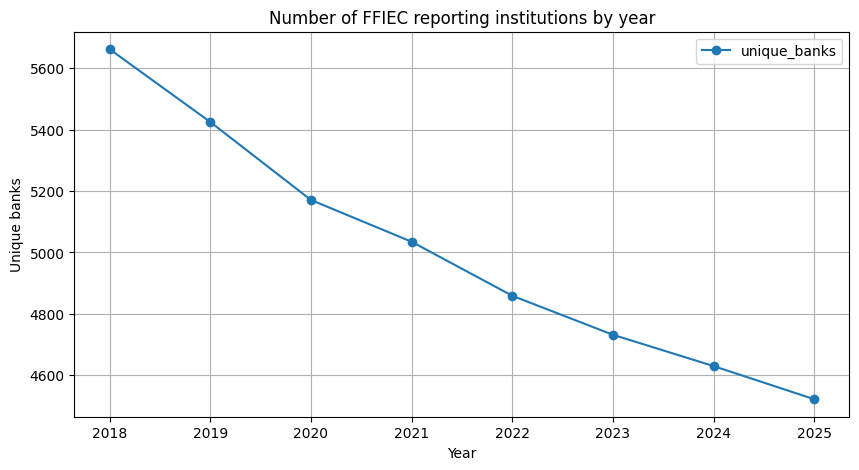

In [94]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))

year_counts.plot(
    x="year",
    y="unique_banks",
    kind="line",
    marker="o",
    ax=plt.gca()
)

plt.xlabel("Year")
plt.ylabel("Unique banks")
plt.title("Number of FFIEC reporting institutions by year")
plt.grid(True)
plt.show()

In [95]:
master_path = (
    PROCESSED_DIR /
    "bank_quarter_panel.parquet"
)

bank_quarter_panel.to_parquet(
    master_path,
    index=False,
    engine="pyarrow"
)

print("Master panel saved:")
print(master_path)

Master panel saved:
/Users/irfanhussain/Desktop/systemic-risk-project/data/processed/bank_quarter_panel.parquet


In [96]:
display(
    bank_quarter_panel[
        [
            "IDRSSD",
            "Reporting Period End Date",
            "Financial Institution Name",
            "Financial Institution State",
            "total_assets",
            "total_equity",
            "loans_net_unearned",
            "total_deposits",
            "total_nonaccrual",
            "quarterly_net_income",
            "quarterly_net_interest_income",
            "capital_ratio",
            "loan_to_asset",
            "deposit_to_asset",
            "nonaccrual_to_loan",
            "roa",
            "nii_to_asset"
        ]
    ].head(20)
)

,IDRSSD,Reporting Period End Date,Financial Institution Name,Financial Institution State,total_assets,total_equity,loans_net_unearned,total_deposits,total_nonaccrual,quarterly_net_income,quarterly_net_interest_income,capital_ratio,loan_to_asset,deposit_to_asset,nonaccrual_to_loan,roa,nii_to_asset
0,1000052,2018-03-31,WASHINGTON COUNTY BANK,NE,360585,36098,290892,301420.0,1225,1157.0,3216.0,0.10011,0.806722,0.835919,0.004211,0.003209,0.008919
1,1000052,2018-06-30,WASHINGTON COUNTY BANK,NE,365600,37405,294626,295886.0,1264,1381.0,3319.0,0.102311,0.80587,0.809316,0.004290,0.003777,0.009078
2,1000052,2018-09-30,WASHINGTON COUNTY BANK,NE,375344,38406,299421,313493.0,390,1139.0,3471.0,0.102322,0.797724,0.835215,0.001303,0.003035,0.009248
3,1000052,2018-12-31,WASHINGTON COUNTY BANK,NE,432110,39318,297653,376407.0,745,1434.0,3680.0,0.090991,0.688836,0.871091,0.002503,0.003319,0.008516
4,1000052,2019-03-31,WASHINGTON COUNTY BANK,NE,416494,40553,303888,362976.0,865,1260.0,3608.0,0.097368,0.729634,0.871504,0.002846,0.003025,0.008663
5,1000052,2019-06-30,WASHINGTON COUNTY BANK,NE,429465,42300,318289,376572.0,623,1387.0,3806.0,0.098495,0.741129,0.87684,0.001957,0.00323,0.008862
6,1000052,2019-09-30,WASHINGTON COUNTY BANK,NE,433506,43302,313770,377242.0,521,1562.0,3842.0,0.099888,0.723796,0.870212,0.001660,0.003603,0.008863
7,1000052,2019-12-31,WASHINGTON COUNTY BANK,NE,441212,43903,323025,381997.0,454,1416.0,3826.0,0.099505,0.732131,0.86579,0.001405,0.003209,0.008672
8,1000052,2020-03-31,WASHINGTON COUNTY BANK,NE,424954,45510,336910,364391.0,499,1459.0,3804.0,0.107094,0.792815,0.857483,0.001481,0.003433,0.008952
9,1000052,2020-06-30,WASHINGTON COUNTY BANK,NE,468217,46775,359453,397917.0,648,1344.0,3821.0,0.0999,0.767706,0.849856,0.001803,0.00287,0.008161


In [97]:
missing_naccrual_ratio = bank_quarter_panel[
    bank_quarter_panel["nonaccrual_to_loan"].isna()
][
    [
        "IDRSSD",
        "Reporting Period End Date",
        "loans_net_unearned",
        "total_nonaccrual"
    ]
]

display(
    missing_naccrual_ratio.head(20)
)

,IDRSSD,Reporting Period End Date,loans_net_unearned,total_nonaccrual
5620,1160853,2018-03-31,0,0
5621,1160853,2018-06-30,0,0
5622,1160853,2018-09-30,0,0
5623,1160853,2018-12-31,0,0
6908,1216826,2023-06-30,0,0
6909,1216826,2023-09-30,0,0
6910,1216826,2023-12-31,0,0
6911,1216826,2024-03-31,0,0
6912,1216826,2024-06-30,0,0
9114,1369870,2018-03-31,0,0


In [98]:
print(
    "Missing ratio with zero loans:",
    (
        missing_naccrual_ratio["loans_net_unearned"] == 0
    ).sum()
)

print(
    "Missing ratio with missing loans:",
    missing_naccrual_ratio["loans_net_unearned"]
    .isna()
    .sum()
)

print(
    "Missing ratio with positive loans:",
    (
        missing_naccrual_ratio["loans_net_unearned"] > 0
    ).sum()
)

Missing ratio with zero loans: 2935
Missing ratio with missing loans: 0
Missing ratio with positive loans: 0


In [99]:
zero_loan = bank_quarter_panel[
    bank_quarter_panel["loans_net_unearned"] == 0
].copy()

print("Zero-loan observations:", len(zero_loan))

print("\nNonaccrual among zero-loan observations:")
display(
    zero_loan["total_nonaccrual"]
    .value_counts(dropna=False)
    .head(10)
)

print("\nFiling types:")
display(
    zero_loan["Financial Institution Filing Type"]
    .value_counts(dropna=False)
)

print("\nAssets:")
display(
    zero_loan["total_assets"].describe()
)

Zero-loan observations: 2935

Nonaccrual among zero-loan observations:


total_nonaccrual
0        2925
287         2
74490       1
23094       1
3819        1
5071        1
2924        1
236         1
179         1
44          1
Name: count, dtype: Int64


Filing types:


Financial Institution Filing Type
051    1679
041     961
031     295
Name: count, dtype: int64


Assets:


count            2935.0
mean      588119.400341
std      2303513.500112
min               821.0
25%             14145.0
50%             38704.0
75%            156978.5
max          39183000.0
Name: total_assets, dtype: Float64

In [100]:
anomalies = bank_quarter_panel[
    (bank_quarter_panel["loans_net_unearned"] == 0) &
    (bank_quarter_panel["total_nonaccrual"] > 0)
][
    [
        "IDRSSD",
        "Reporting Period End Date",
        "Financial Institution Name",
        "Financial Institution Filing Type",
        "total_assets",
        "loans_net_unearned",
        "total_nonaccrual"
    ]
]

print("Anomalous observations:", len(anomalies))
display(anomalies)

Anomalous observations: 10


,IDRSSD,Reporting Period End Date,Financial Institution Name,Financial Institution Filing Type,total_assets,loans_net_unearned,total_nonaccrual
30771,2590037,2020-06-30,"STATE FARM BANK, FSB",041,15941929,0,74490
30772,2590037,2020-09-30,"STATE FARM BANK, FSB",041,12285312,0,23094
30773,2590037,2020-12-31,"STATE FARM BANK, FSB",041,717331,0,3819
34621,2729677,2018-06-30,NATIONWIDE BANK,041,6209496,0,5071
34622,2729677,2018-09-30,NATIONWIDE BANK,041,5349732,0,2924
49198,3180136,2022-06-30,INDEPENDENCE BANK,041,62380,0,236
49199,3180136,2022-09-30,INDEPENDENCE BANK,041,59695,0,179
52520,3284100,2018-12-31,MARYLAND FINANCIAL BANK,041,11614,0,287
52521,3284100,2019-03-31,MARYLAND FINANCIAL BANK,041,1605,0,287
125614,773171,2020-09-30,MID-CENTRAL NATIONAL BANK,051,137901,0,44


In [101]:
bank_quarter_panel["nonaccrual_to_asset"] = (
    bank_quarter_panel["total_nonaccrual"]
    / bank_quarter_panel["total_assets"]
).replace(
    [np.inf, -np.inf],
    np.nan
)

bank_quarter_panel["has_nonaccrual"] = (
    bank_quarter_panel["total_nonaccrual"] > 0
).astype("int8")

In [102]:
print(
    bank_quarter_panel[
        [
            "nonaccrual_to_asset",
            "nonaccrual_to_loan",
            "has_nonaccrual"
        ]
    ].isna().sum()
)

nonaccrual_to_asset       0
nonaccrual_to_loan     2935
has_nonaccrual            0
dtype: int64


In [103]:
bank_quarter_panel.to_parquet(
    PROCESSED_DIR / "bank_quarter_panel.parquet",
    index=False,
    engine="pyarrow"
)

print("Updated master panel saved.")

Updated master panel saved.


In [104]:
processed_years = {}
processing_results = []

for year in range(2018, 2026):

    print("\n" + "=" * 70)
    print(f"PROCESSING {year}")
    print("=" * 70)

    df_year = process_ffiec_year(year)

    output_path = (
        FFIEC_PROCESSED /
        f"ffiec_{year}.parquet"
    )

    df_year.to_parquet(
        output_path,
        index=False,
        engine="pyarrow"
    )

    processed_years[year] = df_year

    summary = quality_summary(
        df_year,
        year
    )

    processing_results.append(summary)

    print(f"Rows: {len(df_year):,}")
    print(f"Saved: {output_path}")


PROCESSING 2018

Processing 2018...
Merged rows: 22233
Rows: 22,233
Saved: /Users/irfanhussain/Desktop/systemic-risk-project/data/processed/ffiec/ffiec_2018.parquet

PROCESSING 2019

Processing 2019...
Merged rows: 21298
Rows: 21,298
Saved: /Users/irfanhussain/Desktop/systemic-risk-project/data/processed/ffiec/ffiec_2019.parquet

PROCESSING 2020

Processing 2020...
Merged rows: 20411
Rows: 20,411
Saved: /Users/irfanhussain/Desktop/systemic-risk-project/data/processed/ffiec/ffiec_2020.parquet

PROCESSING 2021

Processing 2021...
Merged rows: 19874
Rows: 19,874
Saved: /Users/irfanhussain/Desktop/systemic-risk-project/data/processed/ffiec/ffiec_2021.parquet

PROCESSING 2022

Processing 2022...
Merged rows: 19217
Rows: 19,217
Saved: /Users/irfanhussain/Desktop/systemic-risk-project/data/processed/ffiec/ffiec_2022.parquet

PROCESSING 2023

Processing 2023...
Merged rows: 18731
Rows: 18,731
Saved: /Users/irfanhussain/Desktop/systemic-risk-project/data/processed/ffiec/ffiec_2023.parquet

PRO

In [105]:
for year, df in processed_years.items():
    print(
        year,
        "FDIC Certificate Number"
        in df.columns
    )

2018 True
2019 True
2020 True
2021 True
2022 True
2023 True
2024 True
2025 True


In [106]:
display(
    processed_years[2022][
        [
            "IDRSSD",
            "FDIC Certificate Number",
            "Financial Institution Name",
            "Reporting Period End Date"
        ]
    ].head(10)
)

,IDRSSD,FDIC Certificate Number,Financial Institution Name,Reporting Period End Date
0,1000052,12241,WASHINGTON COUNTY BANK,2022-03-31
1,1000052,12241,WASHINGTON COUNTY BANK,2022-06-30
2,1000052,12241,WASHINGTON COUNTY BANK,2022-09-30
3,1000052,12241,WASHINGTON COUNTY BANK,2022-12-31
4,1000276,26393,PITTSFIELD CO-OPERATIVE BANK,2022-03-31
5,1000276,26393,PITTSFIELD CO-OPERATIVE BANK,2022-06-30
6,1000276,26393,PITTSFIELD CO-OPERATIVE BANK,2022-09-30
7,1000276,26393,PITTSFIELD CO-OPERATIVE BANK,2022-12-31
8,1000641,13107,CITIZENS STATE BANK OF NEW CASTLE,2022-03-31
9,1000641,13107,CITIZENS STATE BANK OF NEW CASTLE,2022-06-30


In [107]:
panel_parts = [
    processed_years[year]
    for year in range(2018, 2026)
]

bank_quarter_panel = pd.concat(
    panel_parts,
    ignore_index=True
)

bank_quarter_panel = (
    bank_quarter_panel
    .sort_values(
        ["IDRSSD", "Reporting Period End Date"]
    )
    .reset_index(drop=True)
)

print("Shape:", bank_quarter_panel.shape)

Shape: (157921, 23)


In [108]:
ffiec_certs = (
    bank_quarter_panel[
        [
            "IDRSSD",
            "FDIC Certificate Number"
        ]
    ]
    .drop_duplicates()
)

print(
    "Unique IDRSSD:",
    ffiec_certs["IDRSSD"].nunique()
)

print(
    "Unique certificate numbers:",
    ffiec_certs["FDIC Certificate Number"].nunique()
)

Unique IDRSSD: 5740
Unique certificate numbers: 5739


In [109]:
cert_per_id = (
    ffiec_certs
    .groupby("FDIC Certificate Number")["IDRSSD"]
    .nunique()
)

print(
    "Certificates linked to multiple IDRSSDs:",
    (cert_per_id > 1).sum()
)

Certificates linked to multiple IDRSSDs: 6


In [110]:
cert_per_id = (
    ffiec_certs
    .groupby("FDIC Certificate Number")["IDRSSD"]
    .nunique()
)

problem_certs = cert_per_id[
    cert_per_id > 1
].index

print("Problem certificates:")
print(problem_certs.tolist())

Problem certificates:
['1213', '15118', '20776', '32541', '57083', '8110']


In [111]:
problem_records = (
    bank_quarter_panel[
        bank_quarter_panel[
            "FDIC Certificate Number"
        ].isin(problem_certs)
    ][
        [
            "FDIC Certificate Number",
            "IDRSSD",
            "Financial Institution Name",
            "Financial Institution State",
            "Reporting Period End Date"
        ]
    ]
    .drop_duplicates()
    .sort_values(
        [
            "FDIC Certificate Number",
            "Reporting Period End Date",
            "IDRSSD"
        ]
    )
)

display(problem_records)

,FDIC Certificate Number,IDRSSD,Financial Institution Name,Financial Institution State,Reporting Period End Date
54255,1213,33268,"ROSCOE STATE BANK, THE",TX,2018-03-31
54256,1213,33268,"ROSCOE STATE BANK, THE",TX,2018-06-30
54257,1213,33268,"ROSCOE STATE BANK, THE",TX,2018-09-30
54258,1213,33268,"ROSCOE STATE BANK, THE",TX,2018-12-31
54259,1213,33268,"ROSCOE STATE BANK, THE",TX,2019-03-31
...,...,...,...,...,...
74113,8110,418856,"STATE BANK OF SPRING HILL, THE",KS,2024-12-31
65108,8110,366854,KENDALL BANK,KS,2025-03-31
65109,8110,366854,KENDALL BANK,KS,2025-06-30
65110,8110,366854,KENDALL BANK,KS,2025-09-30


In [112]:
mapping_summary = (
    problem_records
    .groupby(
        [
            "FDIC Certificate Number",
            "IDRSSD",
            "Financial Institution Name"
        ]
    )
    .agg(
        first_date=("Reporting Period End Date", "min"),
        last_date=("Reporting Period End Date", "max"),
        observations=("Reporting Period End Date", "count")
    )
    .reset_index()
)

display(mapping_summary)

,FDIC Certificate Number,IDRSSD,Financial Institution Name,first_date,last_date,observations
0,1213,2891622,"CORNERSTONE CAPITAL BANK, SSB",2022-12-31,2025-12-31,13
1,1213,33268,"ROSCOE STATE BANK, THE",2018-03-31,2022-09-30,19
2,15118,1002850,FARMERS EXCHANGE BANK,2018-03-31,2019-03-31,5
3,15118,3851427,GATEWAY FIRST BANK,2019-06-30,2025-12-31,27
4,20776,968557,UNION STATE BANK OF FARGO,2018-03-31,2020-09-30,11
5,20776,977951,BORDER BANK,2020-12-31,2025-12-31,21
6,32541,146672,"FLAGSTAR BANK, FSB",2018-03-31,2022-09-30,19
7,32541,694904,"FLAGSTAR BANK, NATIONAL ASSOCIATION",2022-12-31,2025-12-31,13
8,57083,137915,EMIGRANT BANK,2023-12-31,2025-12-31,9
9,57083,3049729,PLUS INTERNATIONAL BANK,2018-03-31,2023-09-30,23


In [113]:
master_path = (
    PROCESSED_DIR /
    "bank_quarter_panel.parquet"
)

bank_quarter_panel.to_parquet(
    master_path,
    index=False,
    engine="pyarrow"
)

print("Saved:", master_path)

Saved: /Users/irfanhussain/Desktop/systemic-risk-project/data/processed/bank_quarter_panel.parquet
